<a href="https://colab.research.google.com/github/chaimae8-lang/PyTorch-FashionMNIST-ComputerVision/blob/main/FashionMNIST_Classification_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn

import torchvision
from torchvision import datasets, transforms, models
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

## 1. Getting a dataset

In [ ]:
# Setup Training data
train_data = datasets.FashionMNIST(
    root="data", # Where to download data to?
    train=True,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

# Setup test data
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 16.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 278kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.14MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.29MB/s]


In [ ]:
len(train_data), len(test_data)

(60000, 10000)

In [ ]:
image, label = train_data[0]
label

9

In [ ]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [ ]:
train_data.class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [ ]:
torch.unique(train_data.targets, return_counts=True)

(tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 tensor([6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]))

In [ ]:
image.shape

torch.Size([1, 28, 28])

* color_channels : 1
* height : 28
* width : 28

The color_channels parameter defines the dimensional depth of an image tensor, quantifying the chromatic components required for its pixel representation—specifically 1 channel for grayscale maps and 3 channels for standard RGB spaces. In PyTorch, this value is by convention positioned as the first axis following the [C, H, W] layout, making a structural permutation to [H, W, C] mandatory when interfacing with external graphic rendering engines like Matplotlib.



** 1.2 Visualizing our data

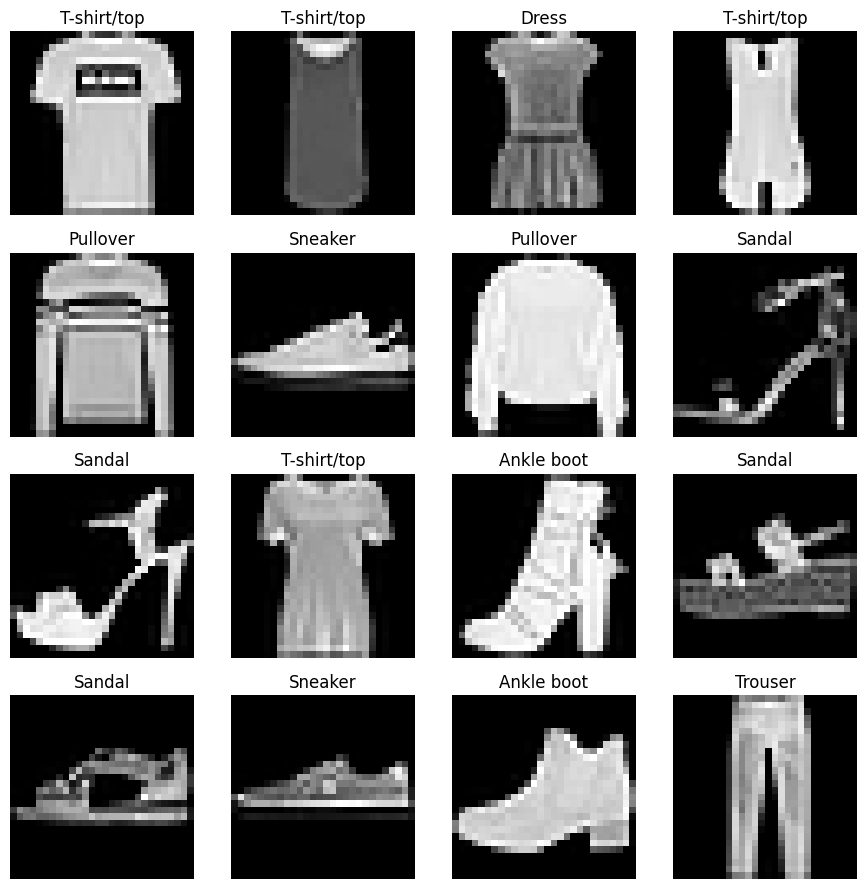

In [ ]:
plt.figure(figsize=(9, 9))
for i in range(1, 17):
  image, label = train_data[i]
  plt.subplot(4, 4, i)
  plt.imshow(image.squeeze(), cmap='gray')
  plt.title(class_names[label])
  plt.axis(False)
plt.tight_layout()

2. Prepare DataLoader

In [ ]:
from torch.utils.data import DataLoader

In PyTorch production pipelines, the shuffle parameter must strictly be set to True for the training loader to break sequential biases and prevent batch-level overfitting. Conversely, it must be set to False for the test loader to ensure exact reproducibility of evaluation metrics and preserve index alignments for error analysis.

In [ ]:
train_dataloader = DataLoader(
    dataset=train_data,
    batch_size=32,
    shuffle=True)

test_dataloader = DataLoader(
    dataset=test_data,
    batch_size=32,
    shuffle=False) # The default value is False

In [ ]:
# 1. iter() transforme le DataLoader en un générateur (un distributeur)
# 2. next() tire le tout premier lot de la pile
train_features_batch, train_labels_batch = next(iter(train_dataloader))

# 3. Affichons les dimensions (shapes) de nos Tenseurs PyTorch
print(f"Shape des images du lot : {train_features_batch.shape}")
print(f"Shape des étiquettes du lot : {train_labels_batch.shape}")

Shape des images du lot : torch.Size([32, 1, 28, 28])
Shape des étiquettes du lot : torch.Size([32])


The next(iter(train_dataloader)) syntax converts the batch manager into Sequential Python iterator before extracting the first sample.

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

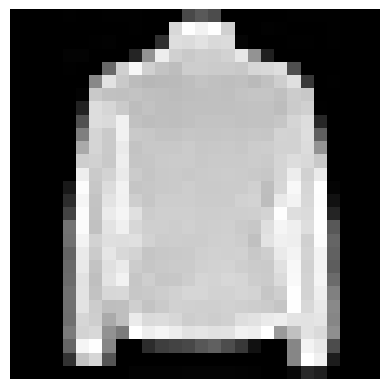

In [ ]:
# Show a sample
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap='gray')
plt.axis(False)

3. Model

In [ ]:
# Create a flatten layer
flatten_model = nn.Flatten()
# Get a single sample
X = train_features_batch[0]


output = flatten_model(X)
print("The Shape before flatten : ", X.shape)
print("The shape after flatten : ", output.shape)

The Shape before flatten :  torch.Size([1, 28, 28])
The shape after flatten :  torch.Size([1, 784])


In [ ]:
class FashionMNISTModelV0(nn.Module):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=784, out_features=10), # Why 784? The output of faltten 28 * 28 is the input.
        nn.Linear(in_features=10, out_features=len(class_names))
    )

  def forward(self, x):
    return self.network(x)

In [ ]:
torch.manual_seed(42)

model_0 = FashionMNISTModelV0()
model_0

FashionMNISTModelV0(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [ ]:
model_0.state_dict()

OrderedDict([('network.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('network.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('network.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.3130, -0.011

In [ ]:
pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 8.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [ ]:
from torchmetrics.classification import MulticlassAccuracy

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

Epoch: 1/5 | Train Loss: 0.5884 - Train Acc: 77.84% | Test Loss: 0.5211 - Test Acc: 80.51%
Epoch: 2/5 | Train Loss: 0.4761 - Train Acc: 82.21% | Test Loss: 0.5140 - Test Acc: 81.01%
Epoch: 3/5 | Train Loss: 0.4536 - Train Acc: 82.91% | Test Loss: 0.5051 - Test Acc: 80.72%
Epoch: 4/5 | Train Loss: 0.4432 - Train Acc: 83.54% | Test Loss: 0.4601 - Test Acc: 82.89%
Epoch: 5/5 | Train Loss: 0.4356 - Train Acc: 83.92% | Test Loss: 0.4710 - Test Acc: 82.65%


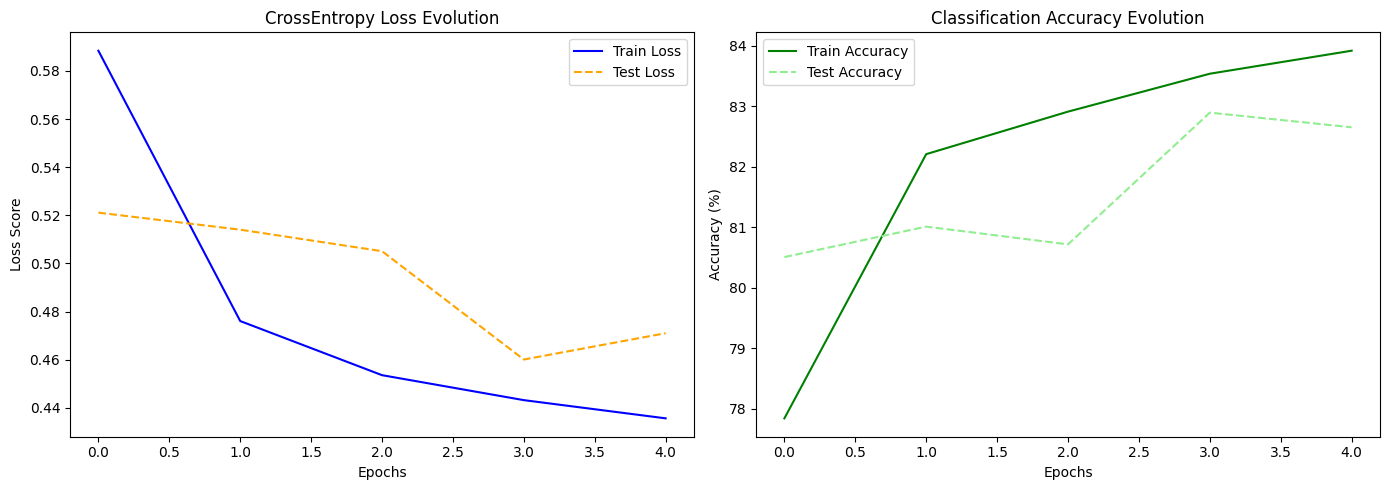

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchmetrics.classification import MulticlassAccuracy

# --- 1. INITIALIZATION ---
model = FashionMNISTModelV0().to(device) # Agnostic device management
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.1)

# Predefined metric deployed on the active hardware
acc_metric = MulticlassAccuracy(num_classes=len(class_names)).to(device)

# History trackers
train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

epochs = 5

# --- 2. OPTIMIZATION AND EVALUATION LOOP ---
for epoch in range(epochs):
    # ==================== PHASE 1: TRAINING ====================
    model.train()
    epoch_train_loss = 0.0
    epoch_train_acc = 0.0

    for batch, (images, labels) in enumerate(train_dataloader):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        # Forward pass & Loss
        train_logits = model(images)
        loss = loss_fn(train_logits, labels)
        epoch_train_loss += loss.item()

        # Direct argmax, dim=1, and .item() extraction
        train_preds = torch.argmax(train_logits, dim=1)
        batch_train_acc = acc_metric(train_preds, labels)
        epoch_train_acc += batch_train_acc.item()

        loss.backward()
        optimizer.step()

    # Compute and log macroeconomic train averages
    avg_train_loss = epoch_train_loss / len(train_dataloader)
    avg_train_acc = (epoch_train_acc / len(train_dataloader)) * 100 # Converted to percentage
    train_loss_history.append(avg_train_loss)
    train_acc_history.append(avg_train_acc)

    # ==================== PHASE 2: TESTING / EVALUATION ====================
    model.eval() # Activate boundary checkpoint
    epoch_test_loss = 0.0
    epoch_test_acc = 0.0

    with torch.inference_mode(): # Cut off gradient computations
        for images, labels in test_dataloader:
            images, labels = images.to(device), labels.to(device)

            # Inference pass
            test_logits = model(images)
            t_loss = loss_fn(test_logits, labels)
            epoch_test_loss += t_loss.item()

            # Metric tracking
            test_preds = torch.argmax(test_logits, dim=1)
            batch_test_acc = acc_metric(test_preds, labels)
            epoch_test_acc += batch_test_acc.item()

    # Compute and log macroeconomic test averages
    avg_test_loss = epoch_test_loss / len(test_dataloader)
    avg_test_acc = (epoch_test_acc / len(test_dataloader)) * 100
    test_loss_history.append(avg_test_loss)
    test_acc_history.append(avg_test_acc)

    print(f"Epoch: {epoch+1}/{epochs} | "
          f"Train Loss: {avg_train_loss:.4f} - Train Acc: {avg_train_acc:.2f}% | "
          f"Test Loss: {avg_test_loss:.4f} - Test Acc: {avg_test_acc:.2f}%")

# ==================== PHASE 3: DUAL SUBPLOT VISUALIZATION ====================
plt.figure(figsize=(14, 5))

# Subplot 1: Loss Evolution Curves
plt.subplot(121)
plt.plot(train_loss_history, label="Train Loss", color="blue")
plt.plot(test_loss_history, label="Test Loss", linestyle="--", color="orange")
plt.title("CrossEntropy Loss Evolution")
plt.xlabel("Epochs")
plt.ylabel("Loss Score")
plt.legend()

# Subplot 2: Accuracy Metrics Tracking
plt.subplot(122)
plt.plot(train_acc_history, label="Train Accuracy", color="green")
plt.plot(test_acc_history, label="Test Accuracy", linestyle="--", color="lightgreen")
plt.title("Classification Accuracy Evolution")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

 20%|██        | 1/5 [00:13<00:52, 13.04s/it]

Epoch: 1/5 | Train Loss: 0.5942 - Train Acc: 77.64% | Test Loss: 0.4927 - Test Acc: 81.02%


 40%|████      | 2/5 [00:26<00:40, 13.38s/it]

Epoch: 2/5 | Train Loss: 0.4758 - Train Acc: 82.35% | Test Loss: 0.5464 - Test Acc: 78.79%


 60%|██████    | 3/5 [00:38<00:25, 12.89s/it]

Epoch: 3/5 | Train Loss: 0.4553 - Train Acc: 83.03% | Test Loss: 0.4700 - Test Acc: 82.03%


 80%|████████  | 4/5 [00:51<00:12, 12.83s/it]

Epoch: 4/5 | Train Loss: 0.4429 - Train Acc: 83.51% | Test Loss: 0.5215 - Test Acc: 80.84%


100%|██████████| 5/5 [01:04<00:00, 12.85s/it]

Epoch: 5/5 | Train Loss: 0.4347 - Train Acc: 83.75% | Test Loss: 0.4881 - Test Acc: 80.97%


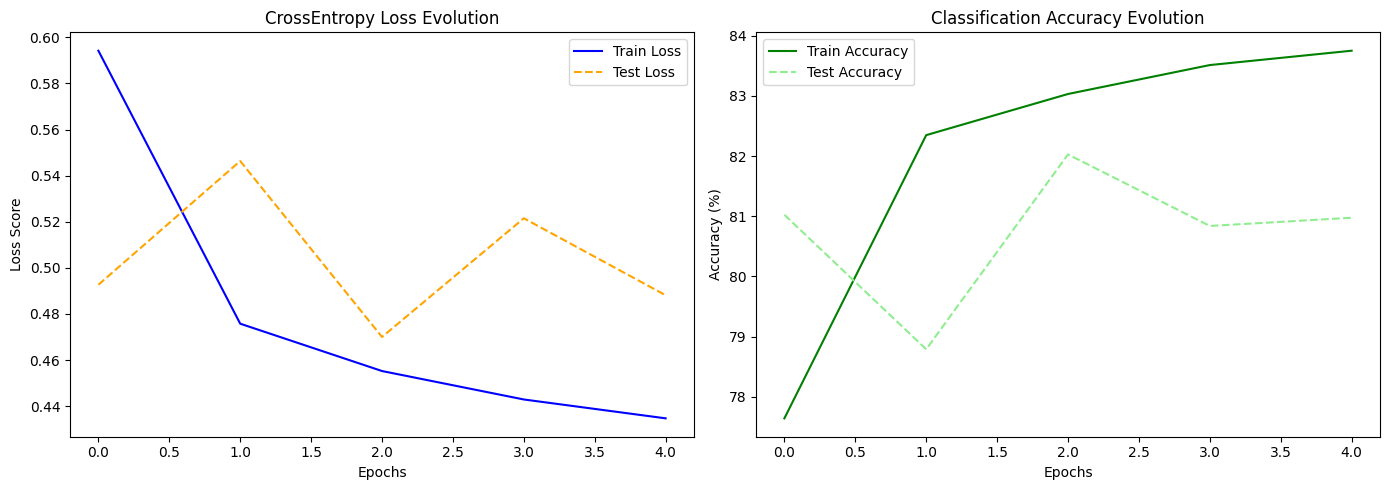

In [ ]:
from tqdm import tqdm
#--- 1. INITIALIZATION ---
model_1 = FashionMNISTModelV0().to(device) # Agnostic device management
loss_fn = nn.CrossEntropyLoss()
optimizer_1 = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

# Predefined metric deployed on the active hardware
acc_metric = MulticlassAccuracy(num_classes=len(class_names)).to(device)

# History trackers
train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

epochs = 5

# --- 2. OPTIMIZATION AND EVALUATION LOOP ---
for epoch in tqdm(range(epochs)):
    # ==================== PHASE 1: TRAINING ====================
    model_1.train()
    epoch_train_loss = 0.0
    epoch_train_acc = 0.0

    for batch, (images, labels) in enumerate(train_dataloader):
        images, labels = images.to(device), labels.to(device)

        optimizer_1.zero_grad()

        # Forward pass & Loss
        train_logits = model_1(images)
        loss = loss_fn(train_logits, labels)
        epoch_train_loss += loss.item()

        # Direct argmax, dim=1, and .item() extraction
        train_preds = torch.argmax(train_logits, dim=1)
        batch_train_acc = acc_metric(train_preds, labels)
        epoch_train_acc += batch_train_acc.item()

        loss.backward()
        optimizer_1.step()

    # Compute and log macroeconomic train averages
    avg_train_loss = epoch_train_loss / len(train_dataloader)
    avg_train_acc = (epoch_train_acc / len(train_dataloader)) * 100 # Converted to percentage
    train_loss_history.append(avg_train_loss)
    train_acc_history.append(avg_train_acc)

    # ==================== PHASE 2: TESTING / EVALUATION ====================
    model_1.eval() # Activate boundary checkpoint
    epoch_test_loss = 0.0
    epoch_test_acc = 0.0

    with torch.inference_mode(): # Cut off gradient computations
        for images, labels in test_dataloader:
            images, labels = images.to(device), labels.to(device)

            # Inference pass
            test_logits = model_1(images)
            t_loss = loss_fn(test_logits, labels)
            epoch_test_loss += t_loss.item()

            # Metric tracking
            test_preds = torch.argmax(test_logits, dim=1)
            batch_test_acc = acc_metric(test_preds, labels)
            epoch_test_acc += batch_test_acc.item()

    # Compute and log macroeconomic test averages
    avg_test_loss = epoch_test_loss / len(test_dataloader)
    avg_test_acc = (epoch_test_acc / len(test_dataloader)) * 100
    test_loss_history.append(avg_test_loss)
    test_acc_history.append(avg_test_acc)

    print(f"Epoch: {epoch+1}/{epochs} | "
          f"Train Loss: {avg_train_loss:.4f} - Train Acc: {avg_train_acc:.2f}% | "
          f"Test Loss: {avg_test_loss:.4f} - Test Acc: {avg_test_acc:.2f}%")

# ==================== PHASE 3: DUAL SUBPLOT VISUALIZATION ====================
plt.figure(figsize=(14, 5))

# Subplot 1: Loss Evolution Curves
plt.subplot(121)
plt.plot(train_loss_history, label="Train Loss", color="blue")
plt.plot(test_loss_history, label="Test Loss", linestyle="--", color="orange")
plt.title("CrossEntropy Loss Evolution")
plt.xlabel("Epochs")
plt.ylabel("Loss Score")
plt.legend()

# Subplot 2: Accuracy Metrics Tracking
plt.subplot(122)
plt.plot(train_acc_history, label="Train Accuracy", color="green")
plt.plot(test_acc_history, label="Test Accuracy", linestyle="--", color="lightgreen")
plt.title("Classification Accuracy Evolution")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

 20%|██        | 1/5 [00:13<00:52, 13.04s/it]

Epoch: 1/5 | Train Loss: 0.6297 - Train Acc: 77.05% | Test Loss: 0.5140 - Test Acc: 81.31%


 40%|████      | 2/5 [00:26<00:39, 13.17s/it]

Epoch: 2/5 | Train Loss: 0.4605 - Train Acc: 82.97% | Test Loss: 0.4728 - Test Acc: 82.28%


 60%|██████    | 3/5 [00:39<00:26, 13.06s/it]

Epoch: 3/5 | Train Loss: 0.4360 - Train Acc: 83.55% | Test Loss: 0.4705 - Test Acc: 82.18%


 80%|████████  | 4/5 [00:52<00:13, 13.16s/it]

Epoch: 4/5 | Train Loss: 0.4223 - Train Acc: 84.21% | Test Loss: 0.4547 - Test Acc: 83.08%


100%|██████████| 5/5 [01:05<00:00, 13.08s/it]

Epoch: 5/5 | Train Loss: 0.4149 - Train Acc: 84.35% | Test Loss: 0.4633 - Test Acc: 82.66%


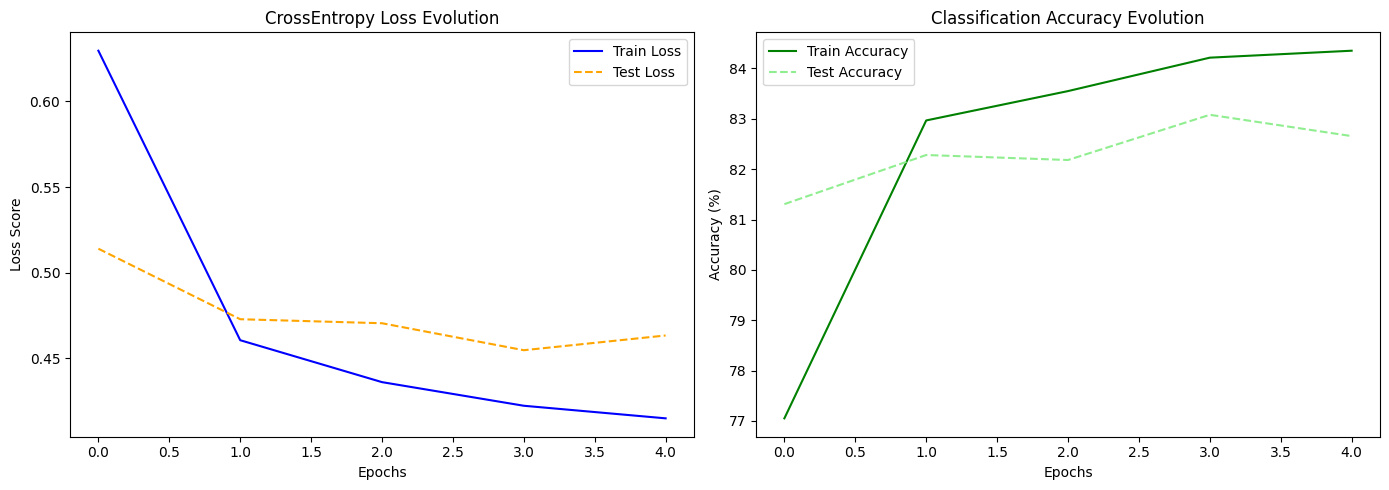

In [ ]:
#--- 1. INITIALIZATION ---
model_2 = FashionMNISTModelV0().to(device) # Agnostic device management
loss_fn = nn.CrossEntropyLoss()
optimizer_2 = torch.optim.Adam(params=model_2.parameters(), lr=0.001)

# Predefined metric deployed on the active hardware
acc_metric = MulticlassAccuracy(num_classes=len(class_names)).to(device)

# History trackers
train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

epochs = 5

# --- 2. OPTIMIZATION AND EVALUATION LOOP ---
for epoch in tqdm(range(epochs)):
    # ==================== PHASE 1: TRAINING ====================
    model_2.train()
    epoch_train_loss = 0.0
    epoch_train_acc = 0.0

    for batch, (images, labels) in enumerate(train_dataloader):
        images, labels = images.to(device), labels.to(device)

        optimizer_2.zero_grad()

        # Forward pass & Loss
        train_logits = model_2(images)
        loss = loss_fn(train_logits, labels)
        epoch_train_loss += loss.item()

        # Direct argmax, dim=1, and .item() extraction
        train_preds = torch.argmax(train_logits, dim=1)
        batch_train_acc = acc_metric(train_preds, labels)
        epoch_train_acc += batch_train_acc.item()

        loss.backward()
        optimizer_2.step()

    # Compute and log macroeconomic train averages
    avg_train_loss = epoch_train_loss / len(train_dataloader)
    avg_train_acc = (epoch_train_acc / len(train_dataloader)) * 100 # Converted to percentage
    train_loss_history.append(avg_train_loss)
    train_acc_history.append(avg_train_acc)

    # ==================== PHASE 2: TESTING / EVALUATION ====================
    model_2.eval() # Activate boundary checkpoint
    epoch_test_loss = 0.0
    epoch_test_acc = 0.0

    with torch.inference_mode(): # Cut off gradient computations
        for images, labels in test_dataloader:
            images, labels = images.to(device), labels.to(device)

            # Inference pass
            test_logits = model_2(images)
            t_loss = loss_fn(test_logits, labels)
            epoch_test_loss += t_loss.item()

            # Metric tracking
            test_preds = torch.argmax(test_logits, dim=1)
            batch_test_acc = acc_metric(test_preds, labels)
            epoch_test_acc += batch_test_acc.item()

    # Compute and log macroeconomic test averages
    avg_test_loss = epoch_test_loss / len(test_dataloader)
    avg_test_acc = (epoch_test_acc / len(test_dataloader)) * 100
    test_loss_history.append(avg_test_loss)
    test_acc_history.append(avg_test_acc)

    print(f"Epoch: {epoch+1}/{epochs} | "
          f"Train Loss: {avg_train_loss:.4f} - Train Acc: {avg_train_acc:.2f}% | "
          f"Test Loss: {avg_test_loss:.4f} - Test Acc: {avg_test_acc:.2f}%")

# ==================== PHASE 3: DUAL SUBPLOT VISUALIZATION ====================
plt.figure(figsize=(14, 5))

# Subplot 1: Loss Evolution Curves
plt.subplot(121)
plt.plot(train_loss_history, label="Train Loss", color="blue")
plt.plot(test_loss_history, label="Test Loss", linestyle="--", color="orange")
plt.title("CrossEntropy Loss Evolution")
plt.xlabel("Epochs")
plt.ylabel("Loss Score")
plt.legend()

# Subplot 2: Accuracy Metrics Tracking
plt.subplot(122)
plt.plot(train_acc_history, label="Train Accuracy", color="green")
plt.plot(test_acc_history, label="Test Accuracy", linestyle="--", color="lightgreen")
plt.title("Classification Accuracy Evolution")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
class FashionMNISTModelV1(nn.Module):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=784, out_features=10), # Why 784? The output of faltten 28 * 28 is the input.
        nn.ReLU(),
        nn.Linear(in_features=10, out_features=len(class_names))
        # No ReLU here: keep raw continuous logits for CrossEntropyLoss
    )

  def forward(self, x):
    return self.network(x)

 20%|██        | 1/5 [00:12<00:51, 12.94s/it]

Epoch: 1/5 | Train Loss: 0.6511 - Train Acc: 76.79% | Test Loss: 0.5109 - Test Acc: 81.12%


 40%|████      | 2/5 [00:26<00:39, 13.07s/it]

Epoch: 2/5 | Train Loss: 0.4604 - Train Acc: 82.48% | Test Loss: 0.4624 - Test Acc: 82.82%


 60%|██████    | 3/5 [00:39<00:26, 13.03s/it]

Epoch: 3/5 | Train Loss: 0.4284 - Train Acc: 83.96% | Test Loss: 0.4461 - Test Acc: 83.24%


 80%|████████  | 4/5 [00:52<00:13, 13.03s/it]

Epoch: 4/5 | Train Loss: 0.4102 - Train Acc: 84.52% | Test Loss: 0.4377 - Test Acc: 83.70%


100%|██████████| 5/5 [01:05<00:00, 13.05s/it]

Epoch: 5/5 | Train Loss: 0.4005 - Train Acc: 84.92% | Test Loss: 0.4341 - Test Acc: 83.82%


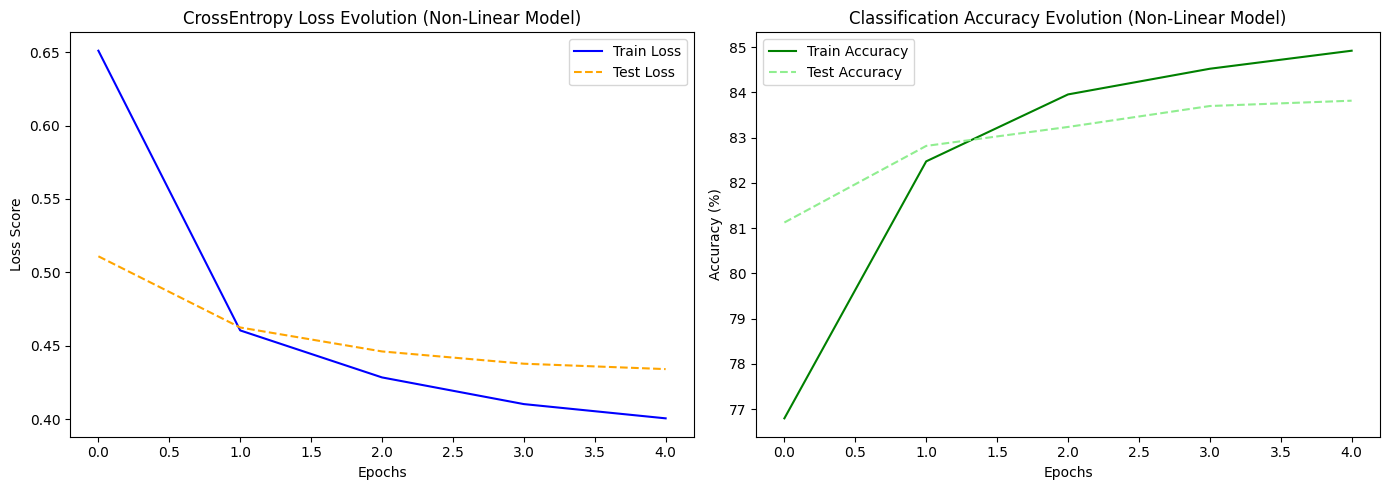

In [ ]:
# Instantiate the new architecture cleanly using index 3
model_3 = FashionMNISTModelV1().to(device)

loss_fn = nn.CrossEntropyLoss()
# RECTIFIED: Optimizer explicitly tied to model_3 parameters
optimizer_3 = torch.optim.Adam(params=model_3.parameters(), lr=0.001)

# Predefined metric deployed onto the active GPU/CPU hardware
acc_metric = MulticlassAccuracy(num_classes=len(class_names)).to(device)

# History trackers
train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

epochs = 5

# ==================== 3. AUTOMATED OPTIMIZATION LOOP ====================
for epoch in tqdm(range(epochs)):
    # -------------------- PHASE 1: TRAINING --------------------
    model_3.train() # RECTIFIED variable references
    epoch_train_loss = 0.0
    epoch_train_acc = 0.0

    for batch, (images, labels) in enumerate(train_dataloader):
        images, labels = images.to(device), labels.to(device)

        optimizer_3.zero_grad()

        # Forward pass & Loss tracking
        train_logits = model_3(images)
        loss = loss_fn(train_logits, labels)
        epoch_train_loss += loss.item()

        # Extract predictions and track training metrics
        train_preds = torch.argmax(train_logits, dim=1)
        batch_train_acc = acc_metric(train_preds, labels)
        epoch_train_acc += batch_train_acc.item()

        loss.backward()
        optimizer_3.step()

    # Compute macroeconomic averages per epoch
    avg_train_loss = epoch_train_loss / len(train_dataloader)
    avg_train_acc = (epoch_train_acc / len(train_dataloader)) * 100
    train_loss_history.append(avg_train_loss)
    train_acc_history.append(avg_train_acc)

    # -------------------- PHASE 2: EVALUATION --------------------
    model_3.eval() # Boundary checkpoint active
    epoch_test_loss = 0.0
    epoch_test_acc = 0.0

    with torch.inference_mode(): # Freeze Autograd computation stream
        for images, labels in test_dataloader:
            images, labels = images.to(device), labels.to(device)

            test_logits = model_3(images)
            t_loss = loss_fn(test_logits, labels)
            epoch_test_loss += t_loss.item()

            test_preds = torch.argmax(test_logits, dim=1)
            batch_test_acc = acc_metric(test_preds, labels)
            epoch_test_acc += batch_test_acc.item()

    # Compute macroeconomic evaluation averages
    avg_test_loss = epoch_test_loss / len(test_dataloader)
    avg_test_acc = (epoch_test_acc / len(test_dataloader)) * 100
    test_loss_history.append(avg_test_loss)
    test_acc_history.append(avg_test_acc)

    print(f"Epoch: {epoch+1}/{epochs} | "
          f"Train Loss: {avg_train_loss:.4f} - Train Acc: {avg_train_acc:.2f}% | "
          f"Test Loss: {avg_test_loss:.4f} - Test Acc: {avg_test_acc:.2f}%")

# ==================== 4. DUAL SUBPLOT RENDERING ====================
plt.figure(figsize=(14, 5))

plt.subplot(121)
plt.plot(train_loss_history, label="Train Loss", color="blue")
plt.plot(test_loss_history, label="Test Loss", linestyle="--", color="orange")
plt.title("CrossEntropy Loss Evolution (Non-Linear Model)")
plt.xlabel("Epochs")
plt.ylabel("Loss Score")
plt.legend()

plt.subplot(122)
plt.plot(train_acc_history, label="Train Accuracy", color="green")
plt.plot(test_acc_history, label="Test Accuracy", linestyle="--", color="lightgreen")
plt.title("Classification Accuracy Evolution (Non-Linear Model)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

# CNN (CONVOLUTIONAL NEURAL NETWORK) ==> TinyVGG

In [ ]:
class FashionMNISTModelV2(nn.Module):
  def __init__(self, input_shape, hidden_units, output_shape):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape, # color channel
                  out_channels=hidden_units, # Learns hidden_units different feature-extraction methods
                  kernel_size=3, # (3, 3)
                  stride=1, # One is by default
                  padding='same'),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units, # hidden_units : The out_channels of the first layer
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding='same'),
        nn.MaxPool2d(kernel_size=2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding='same'),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding='same'),
        nn.MaxPool2d(kernel_size=2)
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units * 7 * 7,
                  out_features=output_shape)
    )

  def forward(self, x):
    x = self.conv_block_1(x)
    x = self.conv_block_2(x)
    x = self.classifier(x)
    return x

In [ ]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_metric,
               device: torch.device):
    """
    Performs a single training epoch step over the mini-batches.
    Computes loss, accuracy, and updates the model's weight matrices.
    """
    model.train()
    train_loss, train_acc = 0.0, 0.0

    for batch, (X, y) in enumerate(dataloader):
        # 1. Send data tensors to the active hardware dev
        X, y = X.to(device), y.to(device)

        # 2. Forward pass: extract raw continuous scores (logits)
        y_pred = model(X)

        # 3. Calculate batch loss and accumulate
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 4. Extract class labels and track accuracy
        preds = torch.argmax(y_pred, dim=1)
        batch_acc = accuracy_metric(preds, y)
        train_acc += batch_acc.item()

        # 5. Execute backpropagation & weights optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Scale macroeconomic averages per epoch
    avg_loss = train_loss / len(dataloader)
    avg_acc = (train_acc / len(dataloader)) * 100

    return avg_loss, avg_acc

In [ ]:
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              accuracy_metric,
              device: torch.device):
    """
    Performs a single evaluation epoch step over the test mini-batches.
    Computes loss and validation accuracy with frozen weights.
    """
    model.eval()
    test_loss, test_acc = 0.0, 0.0

    with torch.inference_mode():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            y_pred = model(X)

            loss = loss_fn(y_pred, y)
            test_loss += loss.item()

            preds = torch.argmax(y_pred, dim=1)
            batch_acc = accuracy_metric(preds, y)
            test_acc += batch_acc.item()

    avg_loss = test_loss / len(dataloader)
    avg_acc = (test_acc / len(dataloader)) * 100

    return avg_loss, avg_acc

Lancement de l'optimisation TinyVGG sur : CPU


 20%|██        | 1/5 [00:59<03:57, 59.42s/it]

Epoch 01 | Train Loss: 0.5221 - Acc: 80.28% | Test Loss: 0.3811 - Acc: 85.42%


 40%|████      | 2/5 [02:01<03:02, 60.99s/it]

Epoch 02 | Train Loss: 0.3377 - Acc: 86.98% | Test Loss: 0.3370 - Acc: 86.79%


 60%|██████    | 3/5 [03:01<02:00, 60.45s/it]

Epoch 03 | Train Loss: 0.2930 - Acc: 88.60% | Test Loss: 0.3012 - Acc: 88.59%


 80%|████████  | 4/5 [04:01<01:00, 60.42s/it]

Epoch 04 | Train Loss: 0.2682 - Acc: 89.64% | Test Loss: 0.2846 - Acc: 88.87%


100%|██████████| 5/5 [04:59<00:00, 59.98s/it]

Epoch 05 | Train Loss: 0.2522 - Acc: 90.12% | Test Loss: 0.2816 - Acc: 88.83%


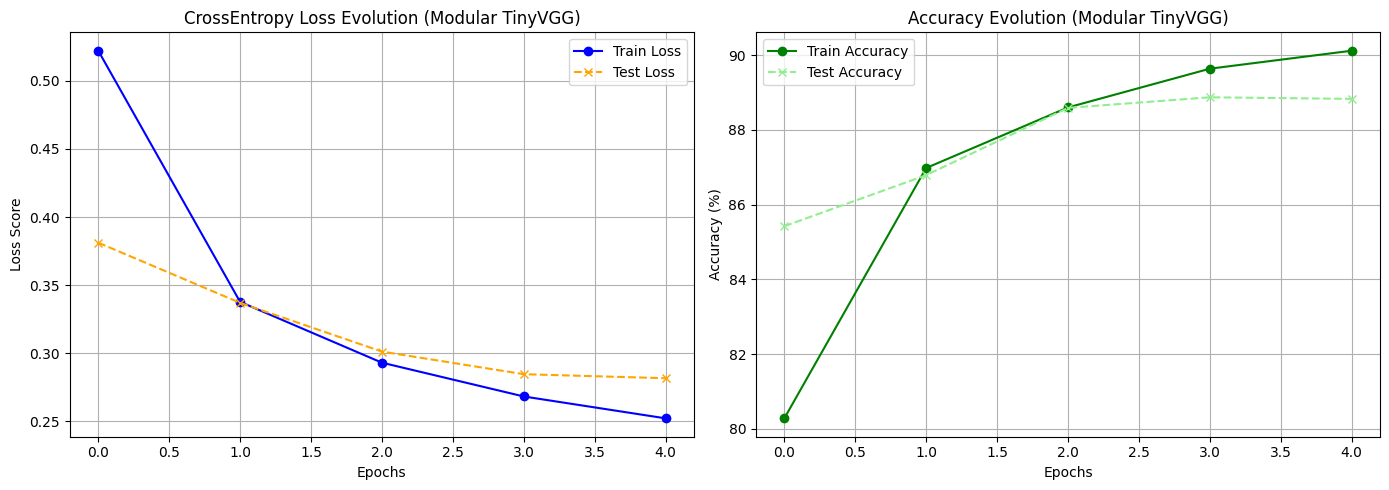

In [ ]:
model_cnn = FashionMNISTModelV2(
    input_shape=1,
    hidden_units=10,
    output_shape=len(class_names)
).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer_3 = torch.optim.Adam(params=model_cnn.parameters(), lr=0.001)
acc_metric = MulticlassAccuracy(num_classes=len(class_names)).to(device)

train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

epochs = 5

print(f"Lancement de l'optimisation TinyVGG sur : {device.upper()}")

for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(
        model=model_cnn, dataloader=train_dataloader, loss_fn=loss_fn,
        optimizer=optimizer_3, accuracy_metric=acc_metric, device=device
    )

    test_loss, test_acc = test_step(
        model=model_cnn, dataloader=test_dataloader, loss_fn=loss_fn,
        accuracy_metric=acc_metric, device=device
    )

    train_loss_history.append(train_loss)
    test_loss_history.append(test_loss)
    train_acc_history.append(train_acc)
    test_acc_history.append(test_acc)

    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f} - Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} - Acc: {test_acc:.2f}%")

plt.figure(figsize=(14, 5))

plt.subplot(121)
plt.plot(train_loss_history, label="Train Loss", color="blue", marker='o')
plt.plot(test_loss_history, label="Test Loss", linestyle="--", color="orange", marker='x')
plt.title("CrossEntropy Loss Evolution (Modular TinyVGG)")
plt.xlabel("Epochs")
plt.ylabel("Loss Score")
plt.grid(True)
plt.legend()

plt.subplot(122)
plt.plot(train_acc_history, label="Train Accuracy", color="green", marker='o')
plt.plot(test_acc_history, label="Test Accuracy", linestyle="--", color="lightgreen", marker='x')
plt.title("Accuracy Evolution (Modular TinyVGG)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Lancement de l'optimisation TinyVGG sur : CPU


 20%|██        | 1/5 [00:56<03:47, 56.89s/it]

Epoch 01 | Train Loss: 0.5097 - Acc: 80.71% | Test Loss: 0.3756 - Acc: 85.44%


 40%|████      | 2/5 [01:54<02:52, 57.51s/it]

Epoch 02 | Train Loss: 0.3215 - Acc: 87.57% | Test Loss: 0.3334 - Acc: 86.86%


 60%|██████    | 3/5 [02:51<01:54, 57.19s/it]

Epoch 03 | Train Loss: 0.2877 - Acc: 88.92% | Test Loss: 0.3115 - Acc: 87.70%


 80%|████████  | 4/5 [03:48<00:57, 57.12s/it]

Epoch 04 | Train Loss: 0.2736 - Acc: 89.55% | Test Loss: 0.3097 - Acc: 88.01%


100%|██████████| 5/5 [04:50<00:00, 58.19s/it]

Epoch 05 | Train Loss: 0.2626 - Acc: 89.76% | Test Loss: 0.3302 - Acc: 87.79%


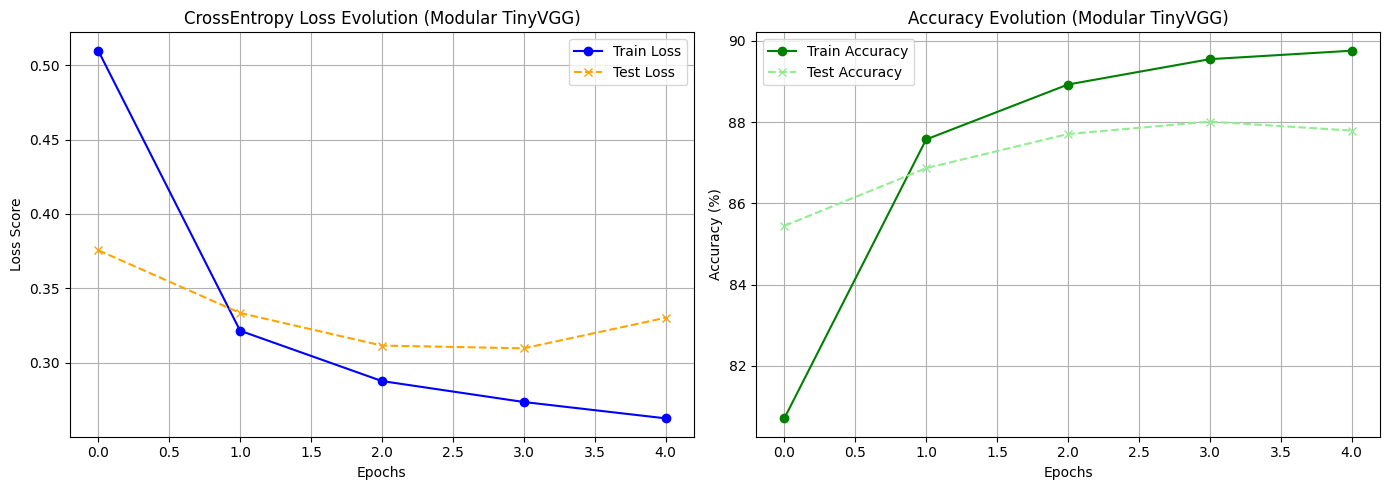

In [ ]:
model_cnn = FashionMNISTModelV2(
    input_shape=1,
    hidden_units=10,
    output_shape=len(class_names)
).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer_3 = torch.optim.SGD(params=model_cnn.parameters(), lr=0.01, momentum=0.9)
acc_metric = MulticlassAccuracy(num_classes=len(class_names)).to(device)

train_loss_history, test_loss_history = [], []
train_acc_history, test_acc_history = [], []

epochs = 5

print(f"Lancement de l'optimisation TinyVGG sur : {device.upper()}")

for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(
        model=model_cnn, dataloader=train_dataloader, loss_fn=loss_fn,
        optimizer=optimizer_3, accuracy_metric=acc_metric, device=device
    )

    test_loss, test_acc = test_step(
        model=model_cnn, dataloader=test_dataloader, loss_fn=loss_fn,
        accuracy_metric=acc_metric, device=device
    )

    train_loss_history.append(train_loss)
    test_loss_history.append(test_loss)
    train_acc_history.append(train_acc)
    test_acc_history.append(test_acc)

    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f} - Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} - Acc: {test_acc:.2f}%")

plt.figure(figsize=(14, 5))

plt.subplot(121)
plt.plot(train_loss_history, label="Train Loss", color="blue", marker='o')
plt.plot(test_loss_history, label="Test Loss", linestyle="--", color="orange", marker='x')
plt.title("CrossEntropy Loss Evolution (Modular TinyVGG)")
plt.xlabel("Epochs")
plt.ylabel("Loss Score")
plt.grid(True)
plt.legend()

plt.subplot(122)
plt.plot(train_acc_history, label="Train Accuracy", color="green", marker='o')
plt.plot(test_acc_history, label="Test Accuracy", linestyle="--", color="lightgreen", marker='x')
plt.title("Accuracy Evolution (Modular TinyVGG)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def make_predictions(model: nn.Module,
                     data: list,
                     device: torch.device = device):
    """
    Takes a list of individual image samples, performs inference on the active device,
    and returns a tensor list of the predicted class labels.
    """
    pred_probs = [] # RECTIFIED: Clear variable naming for class indices
    model.eval()

    with torch.inference_mode():
        for sample in data:
            # 1. Add virtual batch dimension [C, H, W] -> [1, C, H, W] and push to device
            sample = torch.unsqueeze(sample, dim=0).to(device)

            # 2. Extract raw logits from the forward pass
            pred_logit = model(sample)

            # 3. RECTIFIED: Fixed typo, direct argmax, and transfer to CPU for easy plotting
            pred_prob = torch.softmax(pred_logit, dim=1)

            # Append the raw scalar or tensor item to the history tracking list
            pred_probs.append(pred_prob.cpu())

    # 4. CRUCIAL: Stack the list of tensors into a single unified PyTorch tensor and return it
    return torch.stack(pred_probs)

In [ ]:
import random

random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

pred_probs = make_predictions(model=model_cnn, data=test_samples, device=device)

pred_classes = pred_probs.argmax(dim=2).squeeze()

print(f"Classes prédites par TinyVGG : {pred_classes}")
print(f"Classes réelles (Vérité)     : {test_labels}")

Classes prédites par TinyVGG : tensor([5, 3, 7, 4, 3, 0, 4, 7, 1])
Classes réelles (Vérité)     : [5, 1, 7, 4, 3, 0, 4, 7, 1]


In [ ]:
test_samples = [image for image, label in test_data]

pred_probs = make_predictions(model=model_cnn, data=test_samples, device=device)

pred_classes = pred_probs.argmax(dim=2).squeeze()

print(f"Classes prédites par TinyVGG : {pred_classes}")
print(f"Classes réelles (Vérité)     : {test_data.targets}")

Classes prédites par TinyVGG : tensor([9, 2, 1,  ..., 8, 1, 5])
Classes réelles (Vérité)     : tensor([9, 2, 1,  ..., 8, 1, 5])


In [ ]:
from torchmetrics import ConfusionMatrix

conf_mat = ConfusionMatrix(num_classes=len(class_names), task='multiclass')
conf_mat_tensor = conf_mat(preds=pred_classes, target=test_data.targets)
conf_mat_tensor

tensor([[885,   0,  38,  30,   3,   2,  40,   0,   2,   0],
        [  2, 958,   0,  31,   4,   0,   3,   0,   2,   0],
        [ 12,   0, 926,   8,  38,   0,  16,   0,   0,   0],
        [ 21,   0,  19, 930,  20,   0,   9,   0,   1,   0],
        [  2,   1, 137,  35, 784,   0,  41,   0,   0,   0],
        [  0,   0,   0,   1,   0, 973,   0,  20,   0,   6],
        [210,   2, 152,  33,  81,   0, 515,   0,   7,   0],
        [  0,   0,   0,   0,   0,   8,   0, 971,   0,  21],
        [  4,   1,  11,   3,   4,   5,   2,   5, 963,   2],
        [  0,   0,   0,   0,   0,   6,   0,  39,   1, 954]])

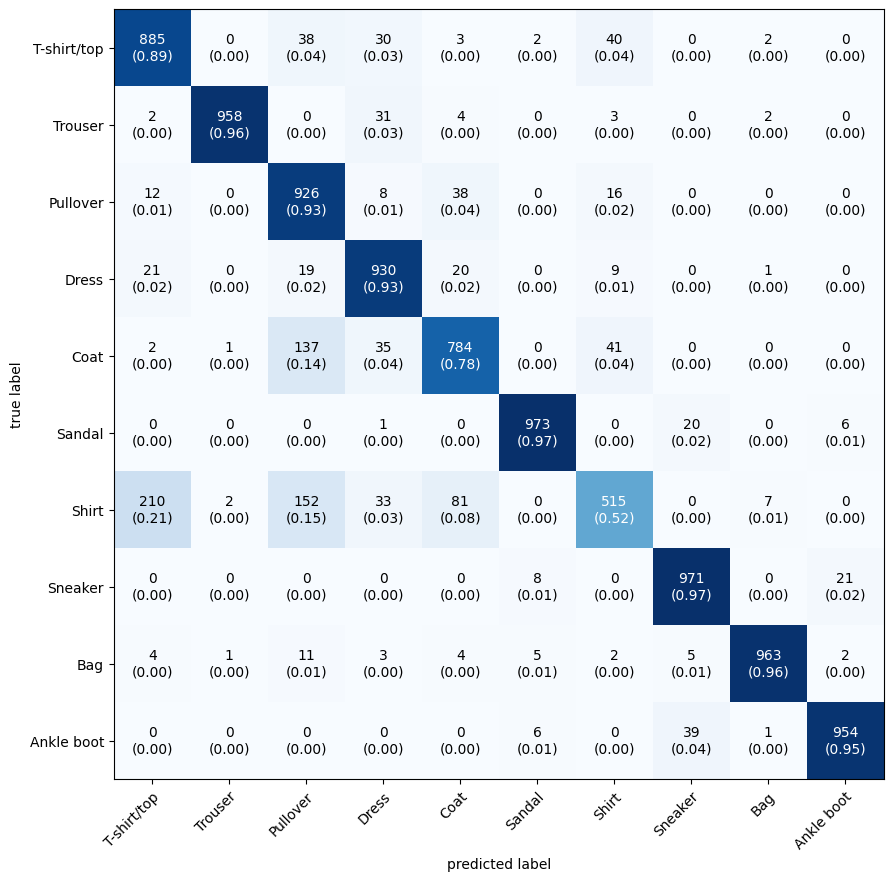

In [ ]:
from mlxtend.plotting import plot_confusion_matrix

fig, ax = plot_confusion_matrix(
    conf_mat=conf_mat_tensor.numpy(),
    class_names=class_names,
    figsize=(10, 10),
    show_normed=True
)